# Kvasir-SEG Sanity Checks

Week 1 task (Balamurali)

This notebook checks three things, per the planning doc:

1. **Correct count** — do we have the expected number of image/mask pairs, with no orphans?
2. **Aligned** — does every mask have the same pixel dimensions as its image, and the same filename stem?
3. **Binary** — are the masks effectively binary (polyp vs. background), allowing for JPEG compression noise?

It also does a quick visual spot-check and cross-checks a few masks against the official
`kavsir_bboxes.json` bounding boxes, since a silently wrong path/parse is the most likely failure mode
at this stage, not a subtle data quality issue.

**Before running:** make sure you've unzipped Kvasir-SEG into `data/kvasir-seg/` as described in
`decisions.md`, and that this notebook is running from the `notebooks/` folder of the repo (that's
where it's meant to live, per the repo layout).

In [1]:
from pathlib import Path
import json
import random
from collections import Counter
from datetime import date

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

%matplotlib inline

## 1. Locate the data

Kvasir-SEG's zip extracts to a `Kvasir-SEG/` folder containing `images/`, `masks/`, and
`kavsir_bboxes.json`. Depending on whether you kept that nesting or flattened it into
`data/kvasir-seg/` directly, this cell finds whichever layout is actually on disk so the rest of the
notebook doesn't care which one you chose.

In [2]:
REPO_ROOT = Path.cwd().parent  # assumes this notebook lives in notebooks/
DATA_ROOT = REPO_ROOT / "polyp-seg-comparison" / "data" / "kvasir-seg"

candidates = [DATA_ROOT, DATA_ROOT / "Kvasir-SEG"]
DATA_DIR = next((c for c in candidates if (c / "images").is_dir() and (c / "masks").is_dir()), None)
DECISIONS_MD = REPO_ROOT / "decisions.md"

if DATA_DIR is None:
    raise FileNotFoundError(
        f"Couldn't find images/ and masks/ under any of {candidates}. "
        "Check that you unzipped Kvasir-SEG into data/kvasir-seg/ (see decisions.md)."
    )

IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
BBOX_PATH = DATA_DIR / "kavsir_bboxes.json"

print(f"Using data directory: {DATA_DIR}")
print(f"  images/: {IMAGES_DIR}")
print(f"  masks/:  {MASKS_DIR}")
print(f"  bboxes:  {BBOX_PATH} (exists: {BBOX_PATH.exists()})")

candidates = [DATA_ROOT, DATA_ROOT / "Kvasir-SEG"]
DATA_DIR = next((c for c in candidates if (c / "images").is_dir() and (c / "masks").is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"Couldn't find images/ and masks/ under any of {candidates}.")

IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
print(f"Using: {DATA_DIR}")

# Fill these in — task 2.1's notes: dataset source URL + the date you actually downloaded it
DATASET_SOURCE = "https://datasets.simula.no/kvasir-seg/"
DOWNLOAD_DATE = "2026-09-20"  # <- set to your actual download date

results_log = {}  # task_id -> summary string, filled in by each cell below

Using data directory: /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/polyp-seg-comparison/data/kvasir-seg
  images/: /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/polyp-seg-comparison/data/kvasir-seg/images
  masks/:  /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/polyp-seg-comparison/data/kvasir-seg/masks
  bboxes:  /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/polyp-seg-comparison/data/kvasir-seg/kavsir_bboxes.json (exists: True)
Using: /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/polyp-seg-comparison/data/kvasir-seg


## 2. Correct count & filename alignment

Kvasir-SEG should have **1000 images and 1000 masks**, one mask per image, matched by filename. This
checks the count and flags any image without a matching mask or vice versa — a common source of
silent bugs later in `dataset.py`.

In [3]:
EXPECTED_COUNT = 1000

image_stems = {p.stem for p in IMAGES_DIR.glob("*") if p.is_file()}
mask_stems = {p.stem for p in MASKS_DIR.glob("*") if p.is_file()}

print(f"Images found: {len(image_stems)} (expected {EXPECTED_COUNT})")
print(f"Masks found:  {len(mask_stems)} (expected {EXPECTED_COUNT})")

missing_masks = sorted(image_stems - mask_stems)
missing_images = sorted(mask_stems - image_stems)

if missing_masks:
    print(f"\n[WARN] {len(missing_masks)} images have no matching mask, e.g. {missing_masks[:5]}")
if missing_images:
    print(f"\n[WARN] {len(missing_images)} masks have no matching image, e.g. {missing_images[:5]}")

if not missing_masks and not missing_images and len(image_stems) == EXPECTED_COUNT:
    print("\nOK: counts match and every image has exactly one matching mask.")

paired_stems = sorted(image_stems & mask_stems)

Images found: 1000 (expected 1000)
Masks found:  1000 (expected 1000)

OK: counts match and every image has exactly one matching mask.


## 3. Dimension alignment

Kvasir-SEG images vary in resolution (this is expected — it's not a fixed-size dataset). What matters
is that each image and its corresponding mask have the **same** dimensions as each other, and that
both are readable. This also records the resolution distribution, which is useful context for
`dataset.py`'s resize/augmentation logic later.

In [4]:
def image_path_for(stem):
    matches = list(IMAGES_DIR.glob(f"{stem}.*"))
    return matches[0] if matches else None

def mask_path_for(stem):
    matches = list(MASKS_DIR.glob(f"{stem}.*"))
    return matches[0] if matches else None

mismatches = []
unreadable = []
size_counter = Counter()

for stem in paired_stems:
    img_p, msk_p = image_path_for(stem), mask_path_for(stem)
    try:
        with Image.open(img_p) as im, Image.open(msk_p) as mk:
            im_size, mk_size = im.size, mk.size
    except Exception as e:
        unreadable.append((stem, str(e)))
        continue
    size_counter[im_size] += 1
    if im_size != mk_size:
        mismatches.append((stem, im_size, mk_size))

print(f"Checked {len(paired_stems)} pairs.")
print(f"Unreadable files: {len(unreadable)}")
print(f"Image/mask size mismatches: {len(mismatches)}")
if mismatches:
    print("  examples:", mismatches[:5])
if unreadable:
    print("  examples:", unreadable[:5])

print("\nTop 5 most common image resolutions:")
for size, count in size_counter.most_common(5):
    print(f"  {size}: {count} images")

Checked 1000 pairs.
Unreadable files: 0
Image/mask size mismatches: 0

Top 5 most common image resolutions:
  (622, 530): 78 images
  (626, 547): 66 images
  (626, 546): 61 images
  (622, 529): 56 images
  (622, 528): 53 images


## 4. Mask binarity check

The masks are distributed as JPEGs, so lossy compression means pixel values won't be *exactly* 0/255
everywhere near an edge — that's expected. What we're checking is that the vast majority of pixels in
each mask cluster tightly around 0 (background) or 255 (polyp), i.e. the mask is *effectively* binary
and safe to threshold (e.g. `mask > 127`) in `dataset.py`.

This runs on a random sample by default (fast); set `SAMPLE_SIZE = None` to check all 1000 masks.

In [5]:
SAMPLE_SIZE = 150       # set to None to check every mask
AMBIGUOUS_MARGIN = 40    # pixel values this far from 0 or 255 are "ambiguous"
random.seed(0)

sample_stems = paired_stems if SAMPLE_SIZE is None else random.sample(paired_stems, min(SAMPLE_SIZE, len(paired_stems)))

ambiguous_fractions = []
for stem in sample_stems:
    with Image.open(mask_path_for(stem)) as mk:
        arr = np.array(mk.convert("L"), dtype=np.int16)
    ambiguous = ((arr > AMBIGUOUS_MARGIN) & (arr < 255 - AMBIGUOUS_MARGIN)).mean()
    ambiguous_fractions.append(ambiguous)

ambiguous_fractions = np.array(ambiguous_fractions)
print(f"Checked {len(sample_stems)} masks.")
print(f"Mean ambiguous-pixel fraction: {ambiguous_fractions.mean():.4%}")
print(f"Max ambiguous-pixel fraction:  {ambiguous_fractions.max():.4%}")
print(f"Masks with >5% ambiguous pixels: {(ambiguous_fractions > 0.05).sum()} / {len(sample_stems)}")

if ambiguous_fractions.mean() < 0.01:
    print("\nOK: masks are effectively binary once thresholded (e.g. mask > 127).")
else:
    print("\n[WARN] Higher-than-expected ambiguity — inspect a few masks visually below before trusting a simple threshold.")

Checked 150 masks.
Mean ambiguous-pixel fraction: 0.0000%
Max ambiguous-pixel fraction:  0.0000%
Masks with >5% ambiguous pixels: 0 / 150

OK: masks are effectively binary once thresholded (e.g. mask > 127).


## 6. Cross-check against `kavsir_bboxes.json` (optional but cheap)

The official bounding-box annotations are a second, independently-produced source of ground truth. If
a mask's polyp extent roughly matches its bbox, that's another point of confidence that files are
correctly aligned (not swapped or mismatched).

In [6]:
if not BBOX_PATH.exists():
    print("kavsir_bboxes.json not found next to images/masks — skipping this check.")
else:
    with open(BBOX_PATH) as f:
        bboxes = json.load(f)

    random.seed(2)
    check_stems = random.sample(paired_stems, min(5, len(paired_stems)))

    for stem in check_stems:
        if stem not in bboxes:
            print(f"{stem}: no bbox entry found")
            continue
        entry = bboxes[stem]
        boxes = entry.get("bbox", entry) if isinstance(entry, dict) else entry

        with Image.open(mask_path_for(stem)) as mk:
            arr = np.array(mk.convert("L")) > 127
        ys, xs = np.where(arr)
        if len(xs) == 0:
            print(f"{stem}: mask is entirely empty — no polyp pixels found")
            continue
        mask_extent = (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
        print(f"{stem}: mask extent (xmin,ymin,xmax,ymax) = {mask_extent}")
        print(f"        json bbox(es) = {boxes}")

cjyzk8qieoboa0848ogj51wwm: mask extent (xmin,ymin,xmax,ymax) = (52, 22, 619, 530)
        json bbox(es) = [{'label': 'polyp', 'xmin': 51, 'ymin': 21, 'xmax': 620, 'ymax': 531}]
cju88trl3ogi208716qvti51b: mask extent (xmin,ymin,xmax,ymax) = (207, 206, 320, 367)
        json bbox(es) = [{'label': 'polyp', 'xmin': 206, 'ymin': 205, 'xmax': 321, 'ymax': 368}]
cju8djdqztu6408506pzhlo18: mask extent (xmin,ymin,xmax,ymax) = (352, 28, 515, 260)
        json bbox(es) = [{'label': 'polyp', 'xmin': 351, 'ymin': 27, 'xmax': 516, 'ymax': 261}]
cju88aq6vo1ij0755c2ey7z7n: mask extent (xmin,ymin,xmax,ymax) = (242, 75, 532, 400)
        json bbox(es) = [{'label': 'polyp', 'xmin': 241, 'ymin': 74, 'xmax': 533, 'ymax': 401}]
cju1b75x63ddl0799sdp0i2j3: mask extent (xmin,ymin,xmax,ymax) = (281, 145, 414, 365)
        json bbox(es) = [{'label': 'polyp', 'xmin': 280, 'ymin': 144, 'xmax': 415, 'ymax': 366}]


## 7. Task 2.4 — Confirm every mask matches an image filename

In [7]:
image_stems = {p.stem for p in IMAGES_DIR.glob("*") if p.is_file()}
mask_stems = {p.stem for p in MASKS_DIR.glob("*") if p.is_file()}

missing_masks = sorted(image_stems - mask_stems)   # images with no mask
missing_images = sorted(mask_stems - image_stems)  # masks with no image
paired_stems = sorted(image_stems & mask_stems)

print(f"Images: {len(image_stems)}  Masks: {len(mask_stems)}  Matched pairs: {len(paired_stems)}")
if missing_masks:
    print(f"[WARN] {len(missing_masks)} images with no matching mask, e.g. {missing_masks[:5]}")
if missing_images:
    print(f"[WARN] {len(missing_images)} masks with no matching image, e.g. {missing_images[:5]}")

if not missing_masks and not missing_images:
    print("PASS: every image has exactly one matching mask, zero mismatches.")
    results_log["2.4"] = f"PASS — {len(paired_stems)}/{len(paired_stems)} filenames matched 1:1, zero mismatches."
else:
    results_log["2.4"] = (
        f"WARN — {len(missing_masks)} images without a mask, {len(missing_images)} masks without an image "
        f"(out of {len(image_stems)} images / {len(mask_stems)} masks)."
    )

Images: 1000  Masks: 1000  Matched pairs: 1000
PASS: every image has exactly one matching mask, zero mismatches.


## 8. Task 2.5 — Check masks are truly binary (black/white only)

In [8]:
SAMPLE_SIZE = 20  # tracker says "10-20 sample masks"
random.seed(0)
sample_stems = random.sample(paired_stems, min(SAMPLE_SIZE, len(paired_stems)))

def mask_path_for(stem):
    matches = list(MASKS_DIR.glob(f"{stem}.*"))
    return matches[0] if matches else None

all_unique_values = set()
per_mask_values = {}
for stem in sample_stems:
    with Image.open(mask_path_for(stem)) as mk:
        arr = np.array(mk.convert("L"))
    uniques = set(np.unique(arr).tolist())
    per_mask_values[stem] = uniques
    all_unique_values |= uniques

print(f"Checked {len(sample_stems)} masks.")
print(f"Union of all pixel values seen: {sorted(all_unique_values)}")

strictly_binary = all_unique_values <= {0, 255}
if strictly_binary:
    print("PASS: only {0, 255} present across the sample — masks are strictly binary.")
    results_log["2.5"] = f"PASS — sampled {len(sample_stems)} masks, only values {{0, 255}} found (strictly binary)."
else:
    # JPEG compression can introduce a few off-values near edges; report how much
    non_binary_fracs = []
    for stem in sample_stems:
        with Image.open(mask_path_for(stem)) as mk:
            arr = np.array(mk.convert("L"))
        non_binary_fracs.append(((arr != 0) & (arr != 255)).mean())
    mean_frac = np.mean(non_binary_fracs)
    print(f"[WARN] Values outside {{0, 255}} found: {sorted(all_unique_values)[:10]}...")
    print(f"Mean fraction of non-{{0,255}} pixels per mask: {mean_frac:.4%}")
    print("This is common with JPEG masks (compression noise near edges) — dataset.py should")
    print("threshold with e.g. `mask > 127` rather than assuming exact equality to 255.")
    results_log["2.5"] = (
        f"WARN — sampled {len(sample_stems)} masks, {mean_frac:.2%} of pixels (mean) fall outside {{0,255}}, "
        f"consistent with JPEG compression noise near edges. dataset.py must threshold (mask > 127), not "
        f"assume exact 0/255."
    )

Checked 20 masks.
Union of all pixel values seen: [0, 1, 2, 3, 4, 5, 6, 7, 8, 247, 248, 249, 250, 251, 252, 253, 254, 255]
[WARN] Values outside {0, 255} found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 247]...
Mean fraction of non-{0,255} pixels per mask: 0.7692%
This is common with JPEG masks (compression noise near edges) — dataset.py should
threshold with e.g. `mask > 127` rather than assuming exact equality to 255.


## 9. Task 2.6 — Visually spot-check 5–10 random image+mask overlay pairs

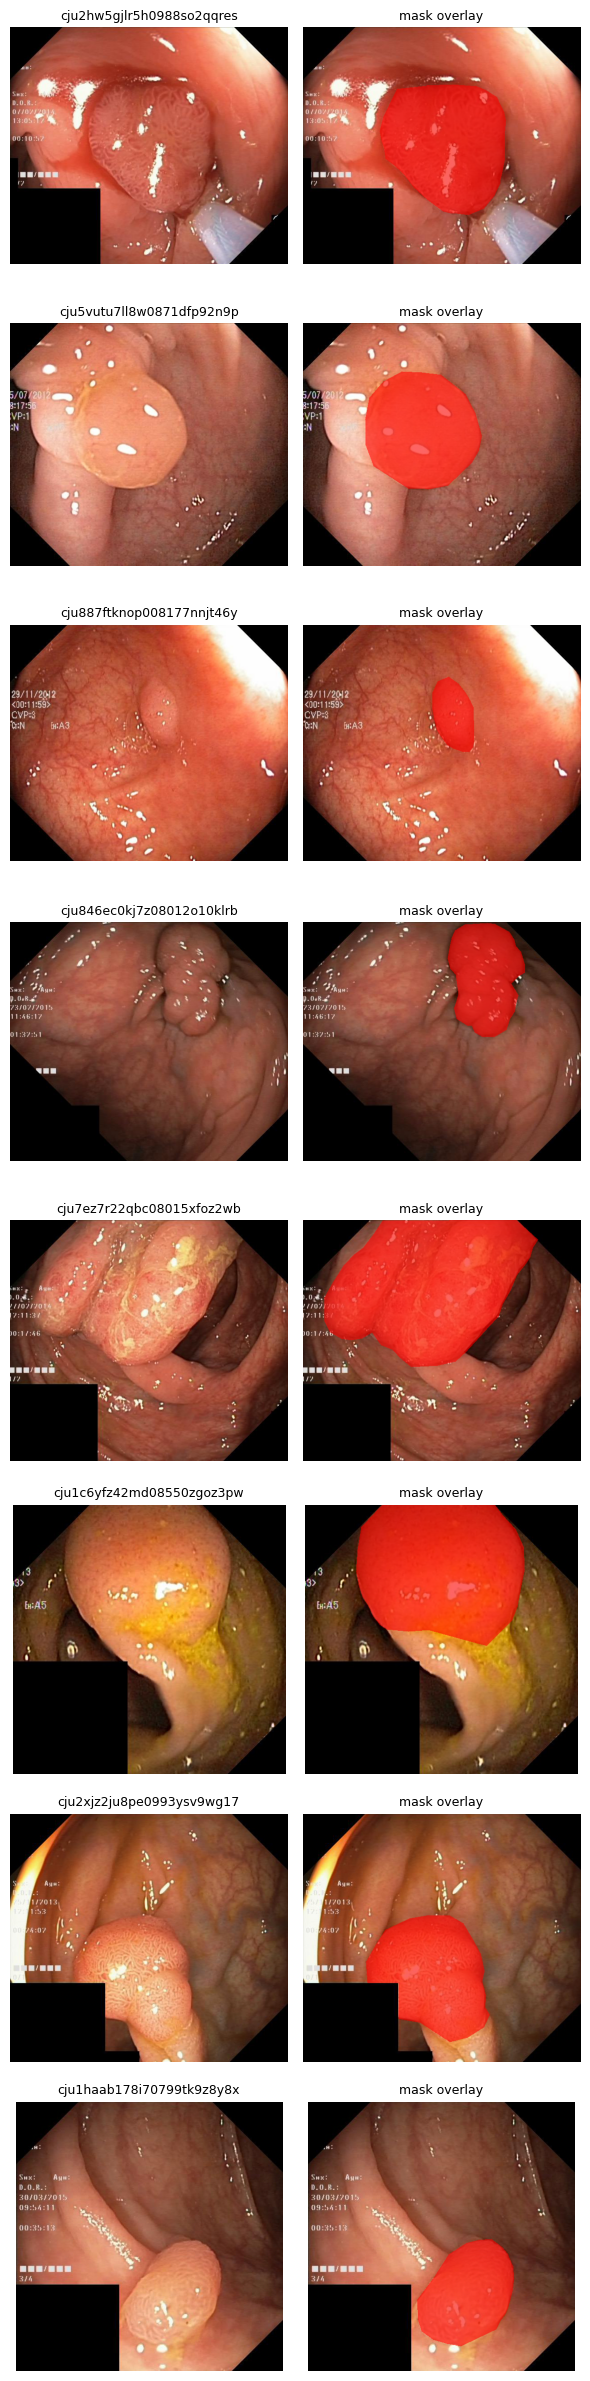

Spot-checked: ['cju2hw5gjlr5h0988so2qqres', 'cju5vutu7ll8w0871dfp92n9p', 'cju887ftknop008177nnjt46y', 'cju846ec0kj7z08012o10klrb', 'cju7ez7r22qbc08015xfoz2wb', 'cju1c6yfz42md08550zgoz3pw', 'cju2xjz2ju8pe0993ysv9wg17', 'cju1haab178i70799tk9z8y8x']
Eyeball the grid above — does the red overlay sit on the actual visible polyp in every row?


In [9]:
N_SPOTCHECK = 8
random.seed(1)
spot_stems = random.sample(paired_stems, min(N_SPOTCHECK, len(paired_stems)))

def image_path_for(stem):
    matches = list(IMAGES_DIR.glob(f"{stem}.*"))
    return matches[0] if matches else None

fig, axes = plt.subplots(len(spot_stems), 2, figsize=(6, 3 * len(spot_stems)))
for row, stem in enumerate(spot_stems):
    with Image.open(image_path_for(stem)) as im, Image.open(mask_path_for(stem)) as mk:
        im = im.convert("RGB")
        mask_bin = np.array(mk.convert("L")) > 127

        axes[row, 0].imshow(im)
        axes[row, 0].set_title(stem, fontsize=9)
        axes[row, 0].axis("off")

        overlay = np.array(im).copy()
        overlay[mask_bin] = (overlay[mask_bin] * 0.4 + np.array([255, 0, 0]) * 0.6).astype(np.uint8)
        axes[row, 1].imshow(overlay)
        axes[row, 1].set_title("mask overlay", fontsize=9)
        axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

print(f"Spot-checked: {spot_stems}")
print("Eyeball the grid above — does the red overlay sit on the actual visible polyp in every row?")

In [10]:
# Run this AFTER you've looked at the grid above and confirmed (or not) that every overlay lines up.
SPOTCHECK_LOOKS_CORRECT = True  # <- set False if you saw a misaligned/wrong pair, and note which stem below

if SPOTCHECK_LOOKS_CORRECT:
    results_log["2.6"] = f"PASS — visually spot-checked {len(spot_stems)} pairs {spot_stems}, all overlays aligned with the visible polyp."
else:
    results_log["2.6"] = f"WARN — visually spot-checked {len(spot_stems)} pairs {spot_stems}, at least one overlay looked misaligned — investigate before trusting dataset.py's pairing logic."

print(results_log["2.6"])

PASS — visually spot-checked 8 pairs ['cju2hw5gjlr5h0988so2qqres', 'cju5vutu7ll8w0871dfp92n9p', 'cju887ftknop008177nnjt46y', 'cju846ec0kj7z08012o10klrb', 'cju7ez7r22qbc08015xfoz2wb', 'cju1c6yfz42md08550zgoz3pw', 'cju2xjz2ju8pe0993ysv9wg17', 'cju1haab178i70799tk9z8y8x'], all overlays aligned with the visible polyp.


## 10. Task 2.7 — Log dataset version and any anomalies in `decisions.md`

Builds one dated entry from the results of 2.4–2.6 above and appends it to `decisions.md`
(matching the table format task 6.1 sets up: `Date | Decision | Rationale | Decided by`).
If `decisions.md` doesn't exist yet, this creates it with that header first.

In [11]:
today = date.today().isoformat()

entry_lines = [
    f"| {today} | Kvasir-SEG sanity checks (2.4–2.6) | Source: {DATASET_SOURCE} · Downloaded: {DOWNLOAD_DATE} · "
    f"{len(image_stems)} images / {len(mask_stems)} masks found in {DATA_DIR.relative_to(REPO_ROOT)} | Balamurali |",
    f"| {today} | 2.4 filename alignment | {results_log.get('2.4', 'not run')} | Balamurali |",
    f"| {today} | 2.5 mask binarity | {results_log.get('2.5', 'not run')} | Balamurali |",
    f"| {today} | 2.6 visual spot-check | {results_log.get('2.6', 'not run')} | Balamurali |",
]

header = "# Decisions Log\n\n| Date | Decision | Rationale | Decided by |\n|---|---|---|---|\n"

if not DECISIONS_MD.exists():
    DECISIONS_MD.write_text(header + "\n".join(entry_lines) + "\n")
    print(f"Created {DECISIONS_MD} and added the entry.")
else:
    with open(DECISIONS_MD, "a") as f:
        f.write("\n".join(entry_lines) + "\n")
    print(f"Appended the entry to {DECISIONS_MD}.")

print("\n--- entry written ---")
print("\n".join(entry_lines))

Appended the entry to /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/decisions.md.

--- entry written ---
| 2026-09-22 | Kvasir-SEG sanity checks (2.4–2.6) | Source: https://datasets.simula.no/kvasir-seg/ · Downloaded: 2026-09-20 · 1000 images / 1000 masks found in polyp-seg-comparison/data/kvasir-seg | Balamurali |
| 2026-09-22 | 2.4 filename alignment | PASS — 1000/1000 filenames matched 1:1, zero mismatches. | Balamurali |
| 2026-09-22 | 2.5 mask binarity | WARN — sampled 20 masks, 0.77% of pixels (mean) fall outside {0,255}, consistent with JPEG compression noise near edges. dataset.py must threshold (mask > 127), not assume exact 0/255. | Balamurali |
| 2026-09-22 | 2.6 visual spot-check | PASS — visually spot-checked 8 pairs ['cju2hw5gjlr5h0988so2qqres', 'cju5vutu7ll8w0871dfp92n9p', 'cju887ftknop008177nnjt46y', 'cju846ec0kj7z08012o10klrb', 'cju7ez7r22qbc08015xfoz2wb', 'cju1c6yfz42md08550zgoz3pw', 'cju2xjz2ju8pe0993ysv9wg17', 'cju1haab178i70799tk9z8y8x'], all overlays ali